In [2]:
# %% 1. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
# Option 2: Double backslashes
df = pd.read_csv("C:\\Users\\RUTHVIK RAJ B R\\Downloads\\archive (5)\\APY.csv")
print("Raw rows:", len(df))

# The csv has extra spaces in column names (like "Area ") and in text, so remove them
df.columns = df.columns.str.strip()
for col in ["State", "District", "Crop", "Season"]:
    df[col] = df[col].str.strip()

# Remove rows with missing values
df = df.dropna()
print("After removing missing values:", len(df))
df = df[(df["Area"] > 0) & (df["Production"] > 0)]
print("After removing zero area/production:", len(df))
df = df.drop_duplicates()
print("After removing duplicates:", len(df))

# Year 2020 has only a few rows, so remove it
df = df[df["Crop_Year"] <= 2019]
print("After removing incomplete year 2020:", len(df))

# Keep only rice (the most important crop, and yields of different crops are not comparable)
df = df[df["Crop"] == "Rice"]
print("Rice rows:", len(df))

# Remove extreme outliers: yields above the 99th percentile are usually data errors
limit = df["Yield"].quantile(0.99)
df = df[df["Yield"] <= limit]
print("After removing extreme yield outliers:", len(df))

df.head()

Raw rows: 345336
After removing missing values: 340383
After removing zero area/production: 338918
After removing duplicates: 338918
After removing incomplete year 2020: 338599
Rice rows: 21550
After removing extreme yield outliers: 21340


,State,District,Crop,Crop_Year,Season,Area,Production,Yield
468,Andaman and Nicobar Island,NICOBARS,Rice,2007,Kharif,7333.75,21864.0,2.98
469,Andaman and Nicobar Island,NICOBARS,Rice,2008,Autumn,7900.00,14730.0,1.86
470,Andaman and Nicobar Island,NICOBARS,Rice,2009,Autumn,8140.00,16600.0,2.04
471,Andaman and Nicobar Island,NICOBARS,Rice,2000,Kharif,102.00,321.0,3.15
472,Andaman and Nicobar Island,NICOBARS,Rice,2001,Kharif,83.00,300.0,3.61


            Area  Production     Yield
count   21340.00    21340.00  21340.00
mean    46143.77   102415.98      2.06
std     65684.55   167693.56      0.94
min         1.00        1.00      0.00
25%      2806.00     4269.75      1.34
50%     16942.00    28923.50      2.03
75%     66355.25   129198.00      2.68
max    687000.00  1710000.00      4.70


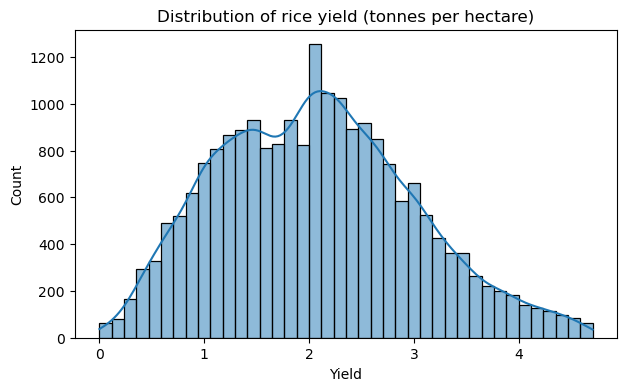

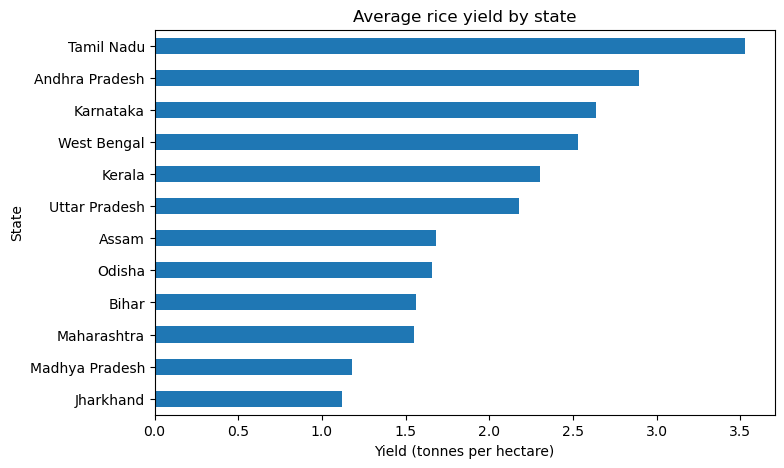

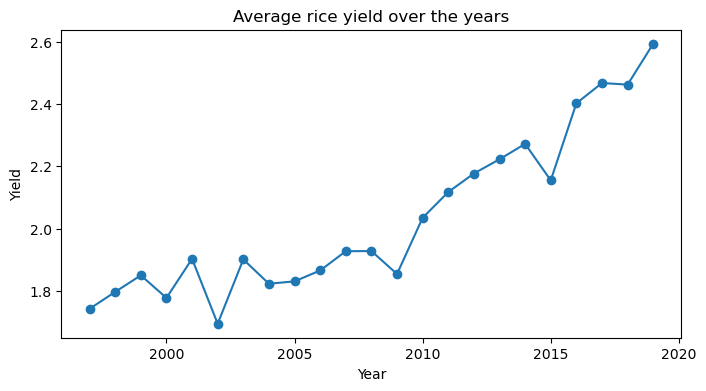

In [5]:
# ## 3. Data analysis (a few plots)

# %% 3a. Basic summary
print(df[["Area", "Production", "Yield"]].describe().round(2))

# %% 3b. How is yield spread?
plt.figure(figsize=(7, 4))
sns.histplot(df["Yield"], bins=40, kde=True)
plt.title("Distribution of rice yield (tonnes per hectare)")
plt.xlabel("Yield")
plt.show()

# %% 3c. Average yield by state (top 12 states with most rows)
top_states = df["State"].value_counts().head(12).index
state_yield = df[df["State"].isin(top_states)].groupby("State")["Yield"].mean().sort_values()

plt.figure(figsize=(8, 5))
state_yield.plot(kind="barh")
plt.title("Average rice yield by state")
plt.xlabel("Yield (tonnes per hectare)")
plt.show()

# %% 3d. Has yield improved over the years?
yearly = df.groupby("Crop_Year")["Yield"].mean()

plt.figure(figsize=(8, 4))
plt.plot(yearly.index, yearly.values, marker="o")
plt.title("Average rice yield over the years")
plt.xlabel("Year")
plt.ylabel("Yield")
plt.show()

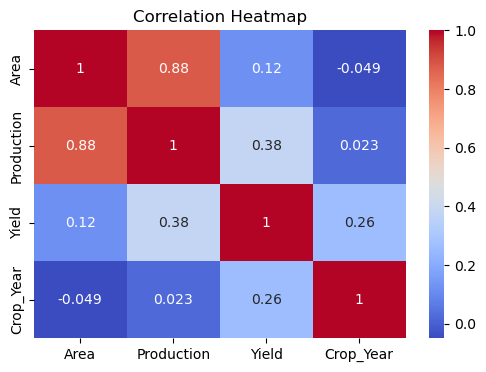

In [28]:
corr = df[["Area", "Production", "Yield", "Crop_Year"]].corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [6]:
# ## 4. Prepare data for the models
# - Text columns (State, Season) become 0/1 columns (one-hot encoding)
# - Train = years up to 2014, Test = 2015 to 2019. We train on the past and predict the future.

# %% 4. Features and split
X = df[["State", "Season", "Area", "Crop_Year"]]
X = pd.get_dummies(X, columns=["State", "Season"], dtype=int)
y = df["Yield"]

train = df["Crop_Year"] <= 2014
test = df["Crop_Year"] > 2014

X_train, X_test = X[train], X[test]
y_train, y_test = y[train], y[test]
print("Train rows:", len(X_train), " Test rows:", len(X_test))

# Scaling puts all columns on a similar range (needed for Linear, Polynomial, MLP)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# For Polynomial Regression we add squared columns so the model can fit curves
X_poly = X.copy()
X_poly["Area_sq"] = X["Area"] ** 2
X_poly["Year_sq"] = X["Crop_Year"] ** 2
scaler_poly = StandardScaler()
Xp_train_s = scaler_poly.fit_transform(X_poly[train])
Xp_test_s = scaler_poly.transform(X_poly[test])

Train rows: 15984  Test rows: 5356


In [19]:
# ## 5. Train the 6 models

# %% 5. Models
results = []
def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    print(f"\n{name}")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")

# 1. Multiple Linear Regression
lin = LinearRegression()
lin.fit(X_train_s, y_train)
pred_lin = lin.predict(X_test_s)
evaluate("Linear Regression", y_test, pred_lin)


Linear Regression
MAE  : 0.508
RMSE : 0.671
R²   : 0.478


In [20]:
# 2. Polynomial Regression (linear regression with squared columns)
poly = LinearRegression()
poly.fit(Xp_train_s, y_train)
pred_poly = poly.predict(Xp_test_s)
evaluate("Polynomial Regression", y_test, pred_poly)


Polynomial Regression
MAE  : 0.522
RMSE : 0.692
R²   : 0.445


In [21]:

# 3. Decision Tree (max_depth stops it from memorising the training data)
tree = DecisionTreeRegressor(max_depth=8, random_state=42)
tree.fit(X_train, y_train)
pred_tree = tree.predict(X_test)
evaluate("Decision Tree", y_test, pred_tree)


Decision Tree
MAE  : 0.650
RMSE : 0.809
R²   : 0.242


In [26]:
# 4. Random Forest (bagging: many trees, average their answers)
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
evaluate("Random Forest", y_test, pred_rf)


Random Forest
MAE  : 0.487
RMSE : 0.654
R²   : 0.504


In [27]:
# 5. Gradient Boosting (boosting: each new tree fixes the errors of the previous ones)
gb = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
pred_gb = gb.predict(X_test)
evaluate("Gradient Boosting", y_test, pred_gb)

# 6. MLP Neural Network (2 hidden layers)
mlp = MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=2000, random_state=42)
mlp.fit(X_train_s, y_train)
pred_mlp = mlp.predict(X_test_s)
evaluate("MLP Neural Network", y_test, pred_mlp)

results_df = pd.DataFrame(results).round(3)
results_df


Gradient Boosting
MAE  : 0.501
RMSE : 0.648
R²   : 0.513

MLP Neural Network
MAE  : 0.558
RMSE : 0.736
R²   : 0.371


,Model,MAE,MSE,RMSE,R2
0,Linear Regression,0.508,0.450,0.671,0.478
1,Polynomial Regression,0.522,0.478,0.692,0.445
2,Decision Tree,0.650,0.654,0.809,0.242
3,Random Forest,0.487,0.427,0.654,0.504
4,Random Forest,0.487,0.427,0.654,0.504
5,Gradient Boosting,0.501,0.420,0.648,0.513
6,MLP Neural Network,0.558,0.542,0.736,0.371
7,Random Forest,0.487,0.427,0.654,0.504
8,Gradient Boosting,0.501,0.420,0.648,0.513
9,MLP Neural Network,0.558,0.542,0.736,0.371


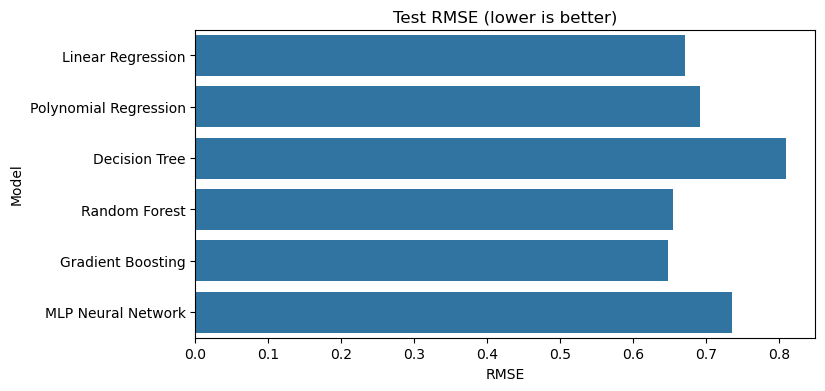

Best model: Gradient Boosting


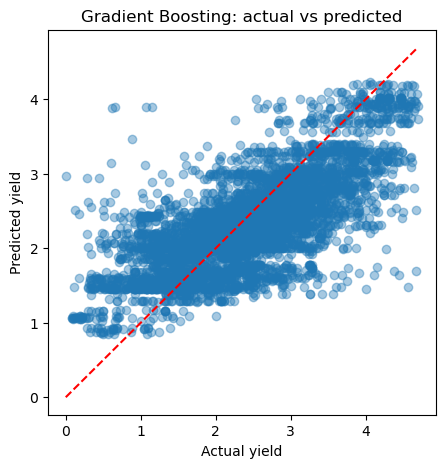

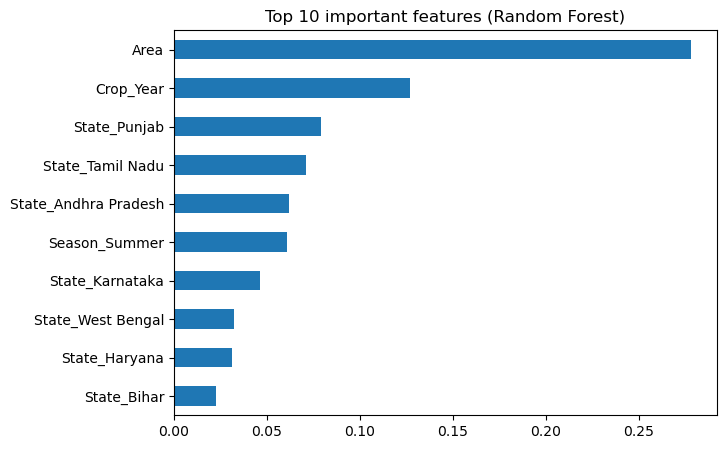

In [25]:





# %% [markdown]
# ## 6. Compare the models

# %% 6a. RMSE of every model
plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="RMSE", y="Model")
plt.title("Test RMSE (lower is better)")
plt.show()

# %% 6b. Best model: actual vs predicted
best = results_df.sort_values("RMSE").iloc[0]["Model"]
print("Best model:", best)

all_preds = {
    "Linear Regression": pred_lin,
    "Polynomial Regression": pred_poly,
    "Decision Tree": pred_tree,
    "Random Forest": pred_rf,
    "Gradient Boosting": pred_gb,
    "MLP Neural Network": pred_mlp,
}
best_pred = all_preds[best]

plt.figure(figsize=(5, 5))
plt.scatter(y_test, best_pred, alpha=0.4)
plt.plot([0, y_test.max()], [0, y_test.max()], "r--")
plt.xlabel("Actual yield")
plt.ylabel("Predicted yield")
plt.title(best + ": actual vs predicted")
plt.show()

# %% 6c. Which features matter most (Random Forest)
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
plt.figure(figsize=(7, 5))
importance.tail(10).plot(kind="barh")
plt.title("Top 10 important features (Random Forest)")
plt.show()

# %% [markdown]
# ## 7. Conclusion (fill in from your own results)
# - Which model had the lowest RMSE and highest R2? Why might it win?
# - Did the simple Linear Regression do worse than the tree models? What does that say about the data?
# - Which features mattered most (state, area, year)?
# - Limitations: no weather or irrigation information in this dataset.